# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'D:\Projects\Machine Learning\Supervised\Regression\medical_cost_prediction\datasets\insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
non_smoker_df = df[df['smoker'] == 'no']
non_smoker_df.shape

(1064, 7)

In [4]:
smoker_df = df[df['smoker'] == 'yes']
smoker_df.shape

(274, 7)

In [5]:
274/1064 * 100

25.75187969924812

#### Observation: 
25.75% of people who applied for the medical insurances are smoker

##### Number of Gender People are there in this dataset

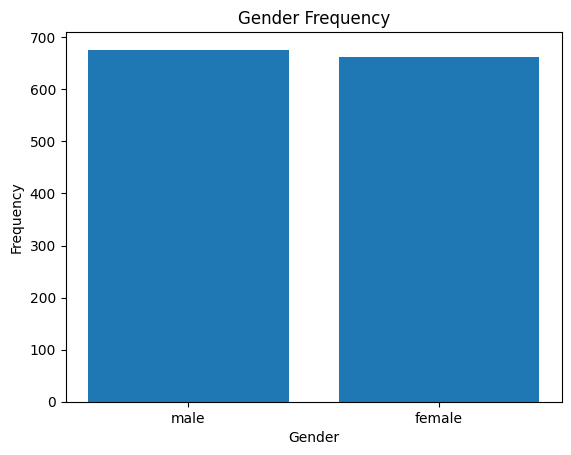

In [6]:
sex = df['sex'].value_counts()

plt.bar(sex.index, sex.values)
plt.title('Gender Frequency')
plt.xlabel('Gender')
plt.ylabel('Frequency')

del sex

#### Observation:
In this dataset, the ratio of the gender is almost equal

sex        female  male
region                 
northeast     161   163
northwest     164   161
southeast     175   189
southwest     162   163


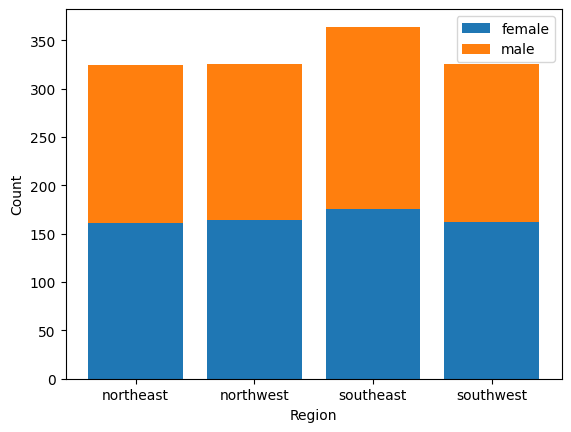

In [7]:
ct = pd.crosstab(df['region'], df['sex'])
print(ct)

plt.bar(ct.index, ct['female'], label='female')
plt.bar(ct.index, ct['male'], bottom=ct['female'], label='male')

plt.xlabel('Region')
plt.ylabel('Count')
plt.legend()
plt.show()

[0 1 2 3]


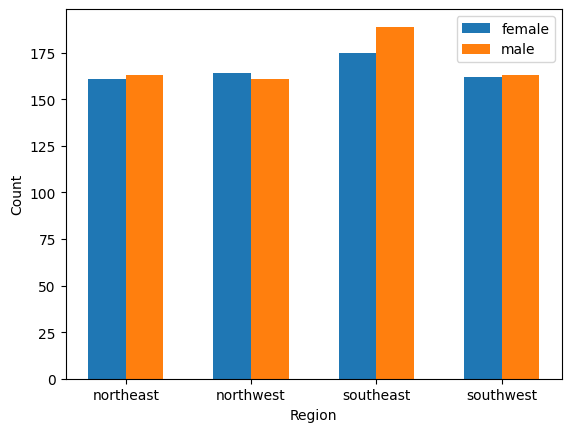

In [8]:
x = np.arange(len(ct.index))
print(x)
width = 0.3

plt.bar(x - width/2, ct['female'], width, label='female')
plt.bar(x + width/2, ct['male'], width, label='male')

plt.xticks(x, ct.index)
plt.xlabel('Region')
plt.ylabel('Count')
plt.legend()
plt.show()

#### Observations:

South east region has slight higher population than other. The rest of the region are almost has same number of population

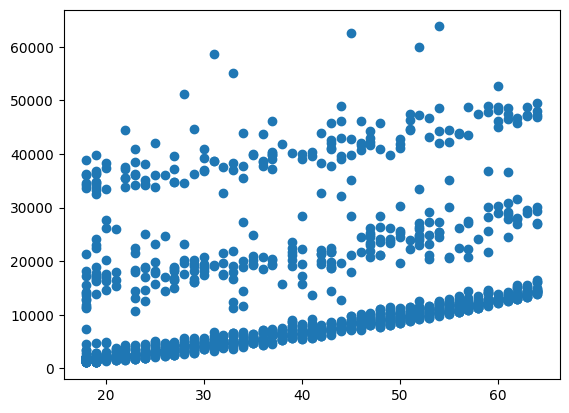

In [9]:
plt.scatter(df['age'], df['charges'])

In [10]:
df[df['age'] < 0]

,age,sex,bmi,children,smoker,region,charges


In [11]:
df[df['children'] < 0]

,age,sex,bmi,children,smoker,region,charges


### BMI based on Age

Text(0, 0.5, 'BMI')

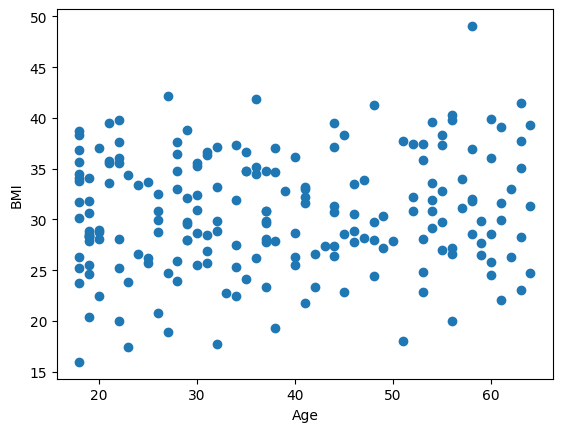

In [12]:
plt.scatter(df['age'][:200], df['bmi'][:200])
plt.xlabel('Age')
plt.ylabel('BMI')

Text(0.5, 0, 'BMI')

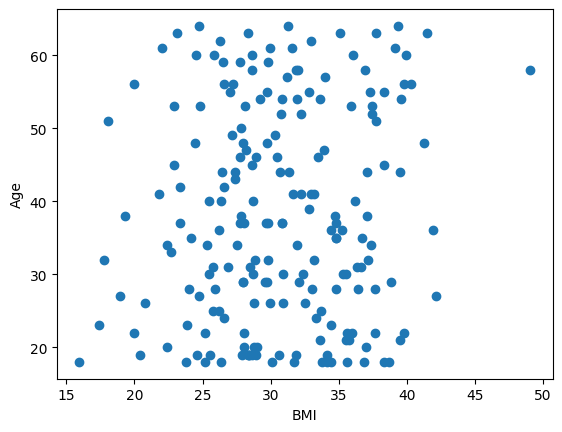

In [13]:
plt.scatter(df['bmi'][:200], df['age'][:200])
plt.ylabel('Age')
plt.xlabel('BMI')

In [14]:
df['age'].describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [15]:
age_range = np.arange(11, 81, 10)
age_range

array([11, 21, 31, 41, 51, 61, 71])

In [16]:
df[df['age'].isin([18, 20])]['age'].value_counts()

age
18    69
20    29
Name: count, dtype: int64

In [18]:
age_range_df = pd.DataFrame()
for age in age_range:
    pd.concat(age_range_df, df[df['age'].isin([a for a in range(age, age+10)])]['age'].value_counts())

age_range_df

TypeError: concat() takes 1 positional argument but 2 were given

In [19]:
age_range_df = pd.DataFrame({
    'age_range': [f'{age}-{age+9}' for age in age_range],
    'count': [
        df['age'].between(age, age + 9).sum()
        for age in age_range
    ]
})

print(age_range_df)

  age_range  count
0     11-20    166
1     21-30    278
2     31-40    257
3     41-50    281
4     51-60    265
5     61-70     91
6     71-80      0


Text(0, 0.5, 'Frequency')

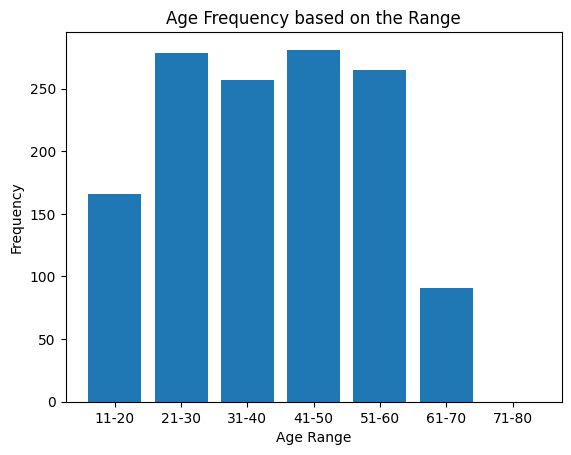

In [20]:
plt.bar(age_range_df['age_range'], age_range_df['count'])
plt.title("Age Frequency based on the Range")
plt.xlabel('Age Range')
plt.ylabel('Frequency')

### Smoker based on age range

In [21]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [22]:
df['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [23]:
smoker = pd.DataFrame({
    'age-range': [f'{age}-{age+9}' for age in age_range],
    'smokers': [
        ((df['age'].between(age, age + 9)) &
         (df['smoker'] == 'yes')).sum()
        for age in age_range
    ],
    'non-smokers': [
        ((df['age'].between(age, age + 9)) &
         (df['smoker'] == 'no')).sum()
        for age in age_range
    ]
})

smoker

,age-range,smokers,non-smokers
0,11-20,39,127
1,21-30,56,222
2,31-40,54,203
3,41-50,61,220
4,51-60,42,223
5,61-70,22,69
6,71-80,0,0


In [24]:

[df[
    df['age'].between(age, age + 9) & df['smoker'] == 'yes'
].shape[0] for age in age_range]


[0, 0, 0, 0, 0, 0, 0]

In [25]:
## Precedency for the boolean operation. Hence brackets are used
[df[
    df['age'].between(age, age + 9) & (df['smoker'] == 'yes')
].shape[0] for age in age_range]


[39, 56, 54, 61, 42, 22, 0]

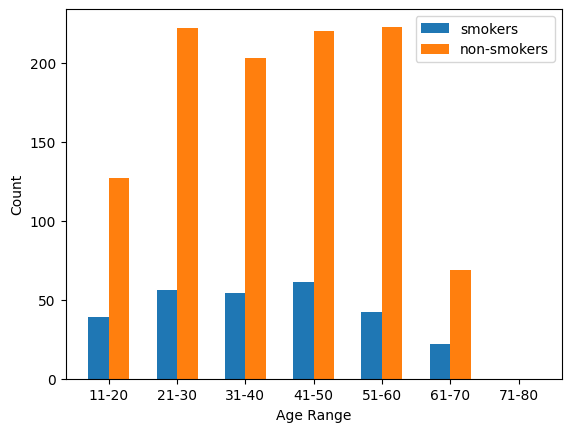

In [26]:
x = np.arange(len(smoker['age-range']))
width = 0.3

plt.bar(x - width/2, smoker['smokers'], width, label='smokers')
plt.bar(x + width/2, smoker['non-smokers'], width, label='non-smokers')

plt.xticks(x, smoker['age-range'])
plt.xlabel('Age Range')
plt.ylabel('Count')
plt.legend()
plt.show()

In [27]:
smoker_df['charges'].describe()

count      274.000000
mean     32050.231832
std      11541.547176
min      12829.455100
25%      20826.244213
50%      34456.348450
75%      41019.207275
max      63770.428010
Name: charges, dtype: float64

### Age Vs Charges

<Axes: xlabel='age', ylabel='charges'>

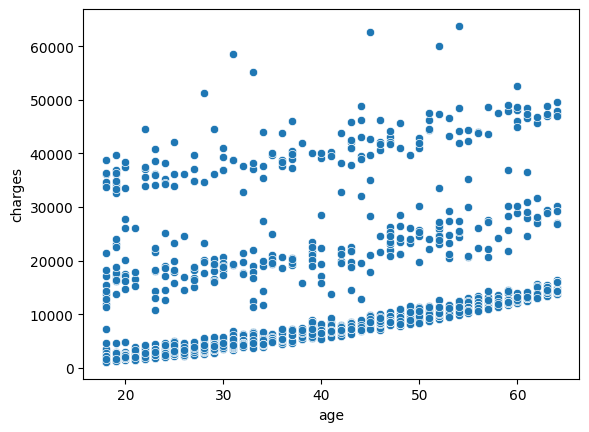

In [28]:
sns.scatterplot(data=df, x="age", y="charges")

<Axes: xlabel='age', ylabel='charges'>

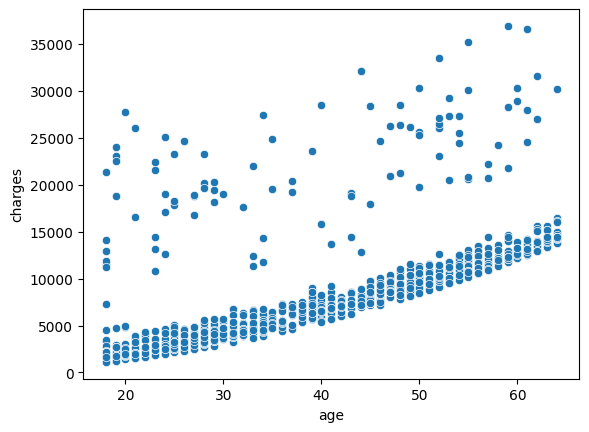

In [29]:
sns.scatterplot(data=non_smoker_df, x = 'age', y='charges')

<Axes: xlabel='age', ylabel='charges'>

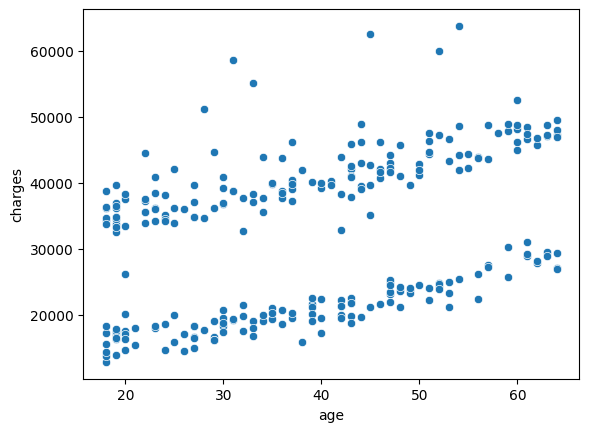

In [30]:
sns.scatterplot(data=smoker_df, x='age', y='charges')

### BMI Vs Charges

<Axes: xlabel='bmi', ylabel='charges'>

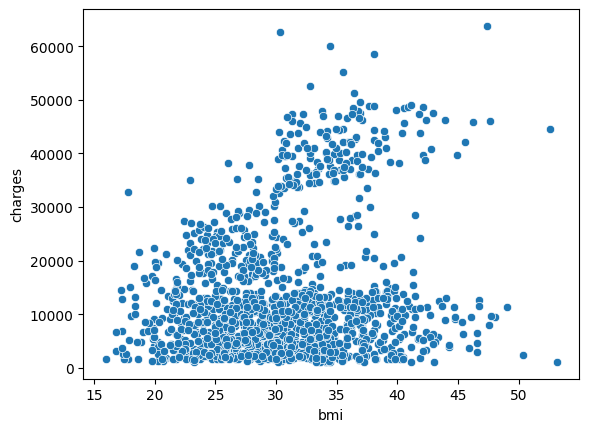

In [31]:
sns.scatterplot(data=df, x="bmi", y="charges")

<Axes: xlabel='bmi', ylabel='charges'>

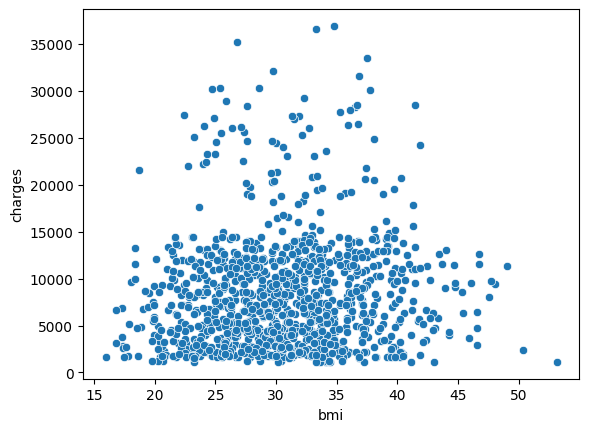

In [32]:
sns.scatterplot(data=non_smoker_df, x="bmi", y="charges")

<Axes: xlabel='bmi', ylabel='charges'>

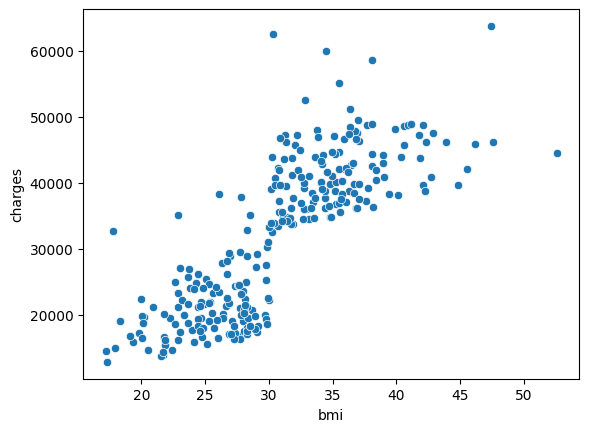

In [33]:
sns.scatterplot(data=smoker_df, x="bmi", y="charges")

<Axes: xlabel='smoker', ylabel='charges'>

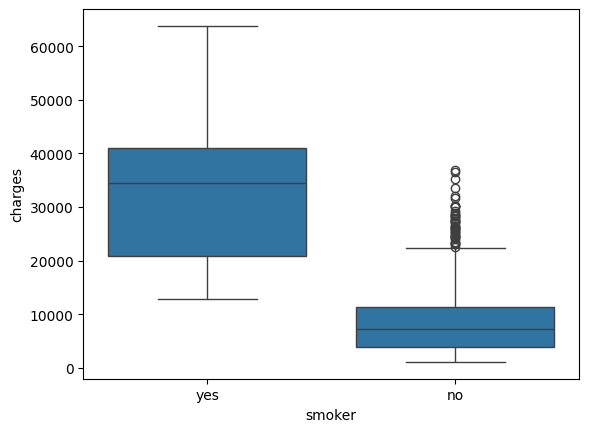

In [34]:
sns.boxplot(data=df, x="smoker", y="charges")

<Axes: xlabel='sex', ylabel='charges'>

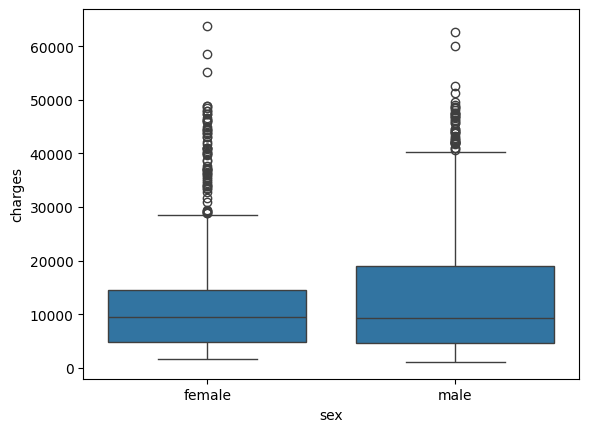

In [35]:
sns.boxplot(data=df, x="sex", y="charges")

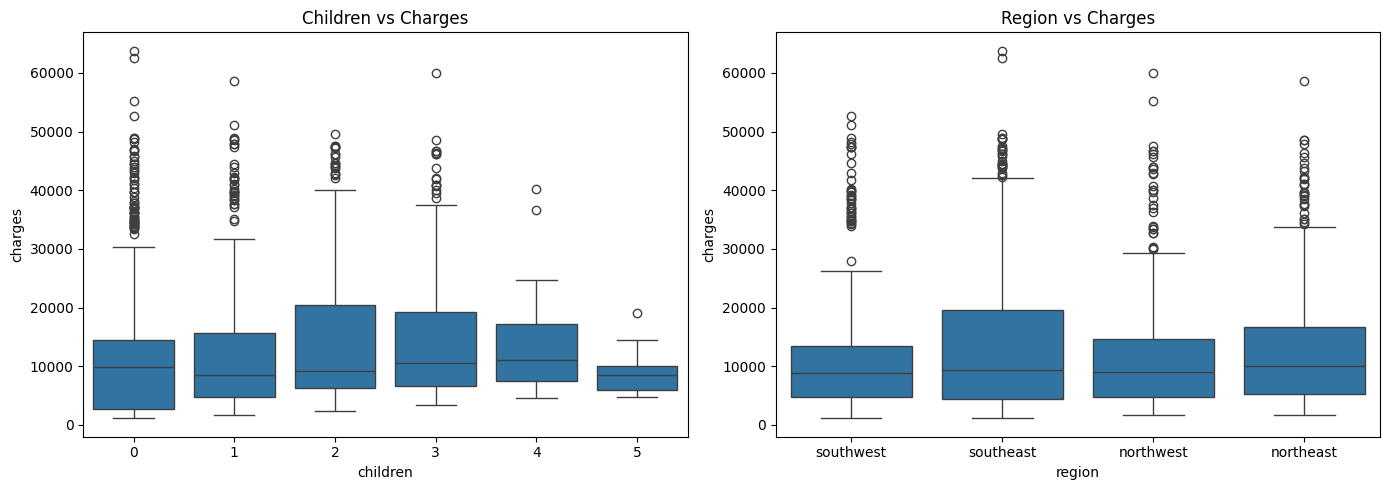

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="children", y="charges", ax=axes[0])
axes[0].set_title("Children vs Charges")

sns.boxplot(data=df, x="region", y="charges", ax=axes[1])
axes[1].set_title("Region vs Charges")

plt.tight_layout()
plt.show()

In [37]:
print(df.groupby("sex")["charges"].mean())
print(df.groupby("smoker")["charges"].mean())
print(df.groupby("region")["charges"].mean())
print(df.groupby("children")["charges"].mean())

sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64
region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64
children
0    12365.975602
1    12731.171832
2    15073.563734
3    15355.318367
4    13850.656311
5     8786.035247
Name: charges, dtype: float64


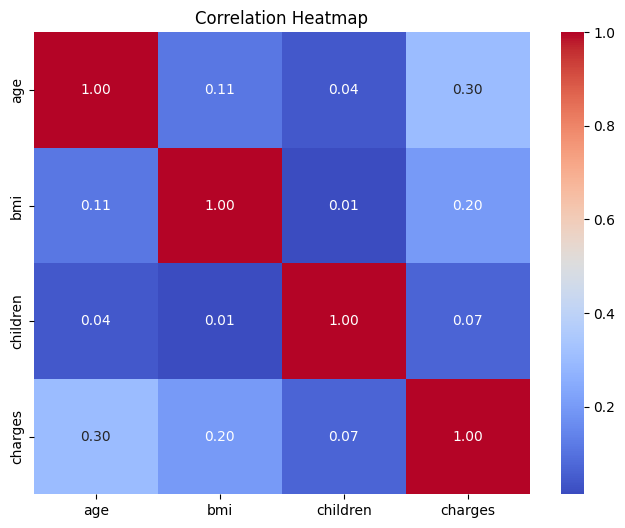

In [38]:
numeric_df = df[
    ["age", "bmi", "children", "charges"]
]

corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

### Analyze the Outliers

In [39]:
numerical_cols = ['age', 'bmi', 'children', 'charges']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outlier count:", len(outliers))
    print("Outlier percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")


Column: age
Lower bound: -9.0
Upper bound: 87.0
Outlier count: 0
Outlier percentage: 0.0 %

Column: bmi
Lower bound: 13.7
Upper bound: 47.290000000000006
Outlier count: 9
Outlier percentage: 0.67 %

Column: children
Lower bound: -3.0
Upper bound: 5.0
Outlier count: 0
Outlier percentage: 0.0 %

Column: charges
Lower bound: -13109.1508975
Upper bound: 34489.350562499996
Outlier count: 139
Outlier percentage: 10.39 %


[[<Axes: > <Axes: >]
 [<Axes: > <Axes: >]]
[<Axes: > <Axes: > <Axes: > <Axes: >]


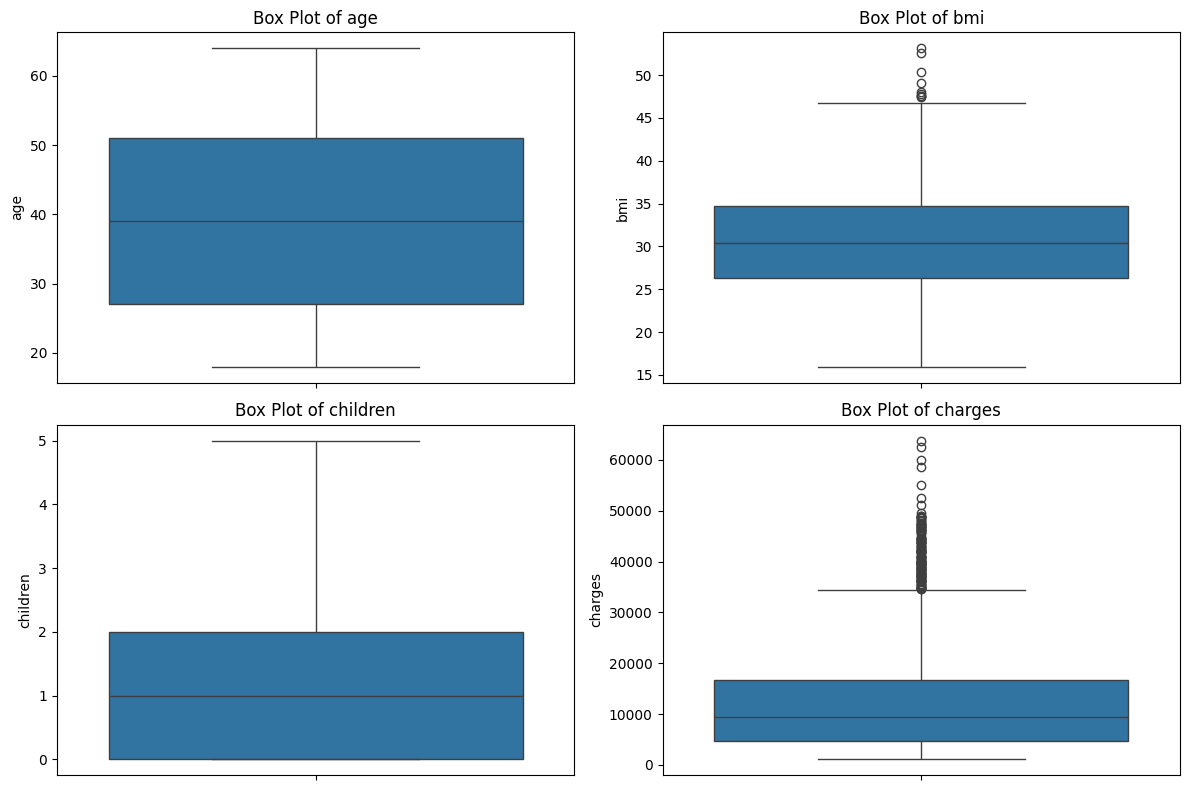

In [40]:
numerical_cols = ['age', 'bmi', 'children', 'charges']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
print(axes)
print(axes.flatten())
for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

In [41]:
charges_Q1 = df["charges"].quantile(0.25)
charges_Q3 = df["charges"].quantile(0.75)

bmi_Q1 = df['bmi'].quantile(0.25)
bmi_Q3 = df['bmi'].quantile(0.75)

charges_IQR = charges_Q3 - charges_Q1
bmi_IQR = bmi_Q3 - bmi_Q1

lower_charges = charges_Q1 - 1.5 * charges_IQR
upper_charges = charges_Q3 + 1.5 * charges_IQR

lower_bmi = bmi_Q1 - 1.5 * bmi_IQR
upper_bmi = bmi_Q3 + 1.5 * bmi_IQR

print(f"Charges: ({lower_charges}, {upper_charges})")
print(f"BMI: ({lower_bmi}, {upper_bmi})")

Charges: (-13109.1508975, 34489.350562499996)
BMI: (13.7, 47.290000000000006)


In [42]:
df[(df['charges'] < lower_charges) | (df['charges'] > upper_charges)]

,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
19,30,male,35.300,0,yes,southwest,36837.46700
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,yes,southwest,38711.00000
30,22,male,35.600,0,yes,southwest,35585.57600
...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420
1313,19,female,34.700,2,yes,southwest,36397.57600


In [43]:
df[(df['bmi'] < lower_bmi) | (df['bmi'] > upper_bmi)]

,age,sex,bmi,children,smoker,region,charges
116,58,male,49.06,0,no,southeast,11381.32540
286,46,female,48.07,2,no,northeast,9432.92530
401,47,male,47.52,1,no,southeast,8083.91980
543,54,female,47.41,0,yes,southeast,63770.42801
847,23,male,50.38,1,no,southeast,2438.05520
860,37,female,47.60,2,yes,southwest,46113.51100
1047,22,male,52.58,1,yes,southeast,44501.39820
1088,52,male,47.74,1,no,southeast,9748.91060
1317,18,male,53.13,0,no,southeast,1163.46270


In [44]:
df.sample(15)

,age,sex,bmi,children,smoker,region,charges
1287,36,female,25.900,1,no,southwest,5472.44900
48,60,female,24.530,0,no,southeast,12629.89670
405,52,female,38.380,2,no,northeast,11396.90020
71,31,male,28.500,5,no,northeast,6799.45800
388,26,female,22.610,0,no,northwest,3176.81590
137,22,male,25.175,0,no,northwest,2045.68525
609,30,male,37.800,2,yes,southwest,39241.44200
1145,52,male,32.775,3,no,northwest,11289.10925
538,46,female,28.050,1,no,southeast,8233.09750
1330,57,female,25.740,2,no,southeast,12629.16560


In [45]:
df_clean = df.copy()

for col in ["charges", "bmi"]:
    lower = df_clean[col].quantile(0.25)
    upper = df_clean[col].quantile(0.75)
    iqr = upper - lower

    lower_bound = lower - 1.5 * iqr
    upper_bound = upper + 1.5 * iqr

    df_clean[col] = df_clean[col].clip(
        lower_bound, upper_bound
    )

In [46]:
df_clean.shape

(1338, 7)

<Axes: ylabel='charges'>

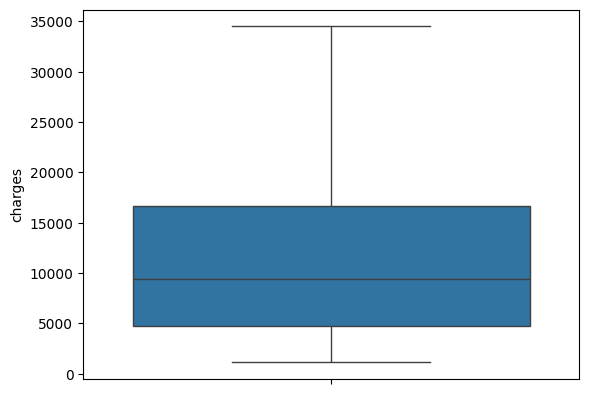

In [47]:
sns.boxplot(df_clean['charges'])

In [48]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1338, 7)
Cleaned shape: (1338, 7)


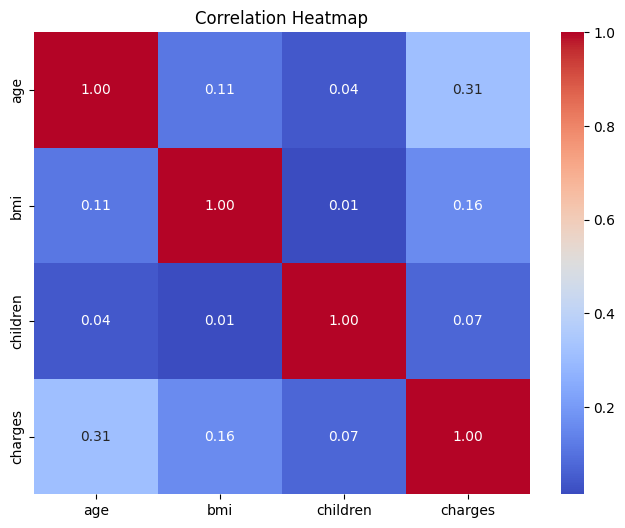

In [49]:
numeric_df = df_clean[
    ["age", "bmi", "children", "charges"]
]

corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [50]:
upper_charges = (
    df["charges"].quantile(0.75)
    + 1.5 * (
        df["charges"].quantile(0.75)
        - df["charges"].quantile(0.25)
    )
)

high_charges = df[df["charges"] > upper_charges].copy()

print("High-charge records:", len(high_charges))

print(
    high_charges[
        ["age", "sex", "bmi", "children",
         "smoker", "region", "charges"]
    ].sort_values("charges", ascending=False).head(20)
)

print("\nSmoking status among high-charge records:")
print(high_charges["smoker"].value_counts())

print("\nAverage charges by smoking status:")
print(df.groupby("smoker")["charges"].agg(
    ["count", "mean", "median"]
).round(2))

High-charge records: 139
      age     sex     bmi  children smoker     region      charges
543    54  female  47.410         0    yes  southeast  63770.42801
1300   45    male  30.360         0    yes  southeast  62592.87309
1230   52    male  34.485         3    yes  northwest  60021.39897
577    31  female  38.095         1    yes  northeast  58571.07448
819    33  female  35.530         0    yes  northwest  55135.40209
1146   60    male  32.800         0    yes  southwest  52590.82939
34     28    male  36.400         1    yes  southwest  51194.55914
1241   64    male  36.960         2    yes  southeast  49577.66240
1062   59    male  41.140         1    yes  southeast  48970.24760
488    44  female  38.060         0    yes  southeast  48885.13561
175    63  female  37.700         0    yes  southwest  48824.45000
530    57    male  42.130         1    yes  southeast  48675.51770
901    60    male  40.920         0    yes  southeast  48673.55880
281    54    male  40.565         3  